# Ejercicio 9
## 1. Calidad de los datos
Se eliminan duplicados exactos y filas incompletas para comparar las mismas lecturas en todas las variables. No se imputan medidas; esto puede introducir sesgo si las ausencias no son aleatorias.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from eficiencia_maquinas import cargar_datos, resumen, seleccionar
original = pd.read_csv('lecturas_maquinas.csv')
print('Filas originales:', len(original))
print('Duplicados:', original.duplicated().sum())
print(original.isna().sum())
datos = cargar_datos('lecturas_maquinas.csv')
print('Filas utilizables:', len(datos))
print('Identificadores repetidos:', datos.registro.duplicated().sum())

Filas originales: 122
Duplicados: 2
registro                   0
maquina                    0
turno                      0
franja                     0
carga_pct                  0
temperatura_c              2
vibracion_mm_s             1
consumo_kwh                0
presion_bar                1
incidencia_proxima_hora    0
dtype: int64
Filas utilizables: 116
Identificadores repetidos: 0


## 2. Eficiencia por máquina
El indicador kWh por punto porcentual de carga aproxima consumo relativo; no mide producción real y puede penalizar cargas bajas por consumo fijo.

,consumo_kwh,carga_pct,indicador
maquina,,,
M01,7.732308,72.974359,0.108288
M02,7.684872,66.974359,0.116996
M03,7.340789,68.447368,0.108402


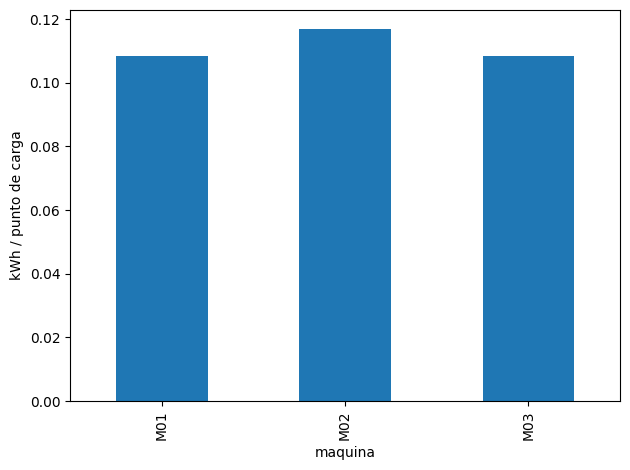

In [2]:
from eficiencia_maquinas import preparar, consumo_por_grupo
datos = preparar(datos)
display(consumo_por_grupo(datos,'maquina'))
consumo_por_grupo(datos,'maquina')['indicador'].plot.bar(ylabel='kWh / punto de carga'); plt.tight_layout(); plt.savefig('eficiencia.jpg'); plt.show()

M02 merece revisión: su indicador medio es superior en los cuatro turnos. Las franjas son comparables, pero la carga y las condiciones no son idénticas.
## 3. Turnos

consumo_kwh  carga_pct  indicador
maquina turno                                   
M01     1         8.140000  76.888889   0.108826
        2         6.925000  64.200000   0.111729
        3         7.661000  72.800000   0.106520
        4         8.244000  78.400000   0.106131
M02     1         7.633000  64.700000   0.119482
        2         6.634444  59.888889   0.113484
        3         8.020000  68.500000   0.118990
        4         8.347000  74.100000   0.115678
M03     1         7.011000  67.400000   0.105487
        2         7.653333  69.555556   0.111066
        3         7.365556  69.555556   0.105686
        4         7.367000  67.500000   0.111366

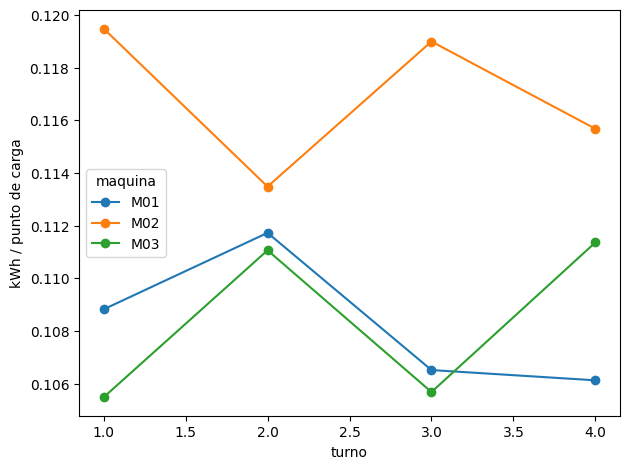

In [3]:
tabla = consumo_por_grupo(datos,['maquina','turno'])
display(tabla)
tabla['indicador'].unstack('maquina').plot(marker='o',ylabel='kWh / punto de carga'); plt.tight_layout(); plt.savefig('turnos.jpg'); plt.show()

M02 destaca especialmente en los turnos 1 y 3 por su indicador medio.
## 4. Selección de revisión
Se eligen lecturas con indicador ≥0,13, un umbral exploratorio relativo a la carga, no al consumo máximo. Pedir producción real, estado de motores y consumo en vacío.

In [4]:
avisos = seleccionar(datos)
display(avisos)
print('Lecturas seleccionadas:',len(avisos))
avisos.to_json('revision_energetica.json',orient='records',indent=2)

,registro,maquina,turno,franja,carga_pct,temperatura_c,vibracion_mm_s,consumo_kwh,presion_bar,incidencia_proxima_hora,indicador
2,M01-01-02,M01,1,2,54,78.9,5.99,7.62,6.43,1,0.141111
4,M01-01-04,M01,1,4,49,63.4,3.21,6.48,7.78,0,0.132245
14,M01-02-04,M01,2,4,40,62.0,2.64,5.36,8.05,0,0.134000
41,M02-01-01,M02,1,1,64,84.5,6.88,8.52,6.32,1,0.133125
49,M02-01-09,M02,1,9,46,79.8,6.40,7.14,6.46,1,0.155217
56,M02-02-06,M02,2,6,42,72.9,3.56,5.70,7.87,0,0.135714
59,M02-02-09,M02,2,9,49,71.9,3.18,6.54,7.18,0,0.133469
61,M02-03-01,M02,3,1,47,73.7,3.35,6.15,7.90,1,0.130851
68,M02-03-08,M02,3,8,57,81.7,6.19,8.28,6.35,1,0.145263
75,M02-04-05,M02,4,5,41,85.3,6.31,6.14,6.29,1,0.149756


Lecturas seleccionadas: 14


## 5. Relaciones entre medidas

,consumo_kwh,carga_pct,temperatura_c,vibracion_mm_s,presion_bar
consumo_kwh,1.000000,0.862895,0.688586,0.672517,-0.470664
carga_pct,0.862895,1.000000,0.443127,0.357877,-0.155562
temperatura_c,0.688586,0.443127,1.000000,0.902896,-0.680632
vibracion_mm_s,0.672517,0.357877,0.902896,1.000000,-0.800113
presion_bar,-0.470664,-0.155562,-0.680632,-0.800113,1.000000


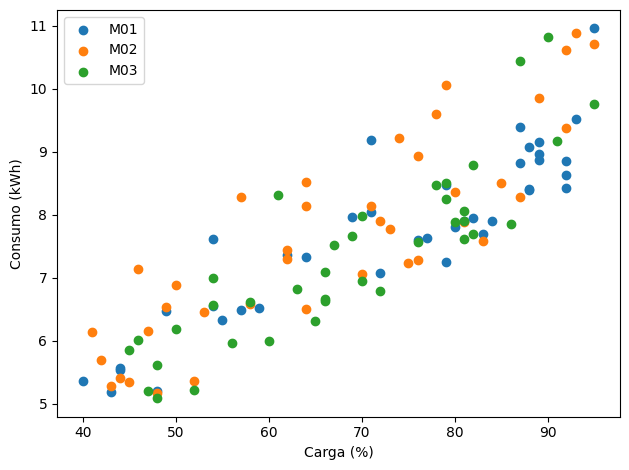

In [5]:
display(datos[['consumo_kwh','carga_pct','temperatura_c','vibracion_mm_s','presion_bar']].corr())
for maquina, grupo in datos.groupby('maquina'):
    plt.scatter(grupo.carga_pct,grupo.consumo_kwh,label=maquina)
plt.xlabel('Carga (%)'); plt.ylabel('Consumo (kWh)'); plt.legend(); plt.tight_layout(); plt.savefig('carga_consumo.jpg'); plt.show()

## Conclusión
El consumo aumenta con la carga, por lo que un máximo no implica ineficiencia. Revisar M02 comparando trabajos equivalentes y mediciones de producción. No se puede atribuir el gasto a una avería sin inspección técnica.